PART I: DATASET ACQUISITION AND UNDERSTANDING

Dataset file used:
facility_reservations - facility_reservations.csv

First 10 records:
Reservation_ID   Facility_Type        User_Category Reservation_Purpose  Lead_Time_Days  Participants  Facility_Capacity  Duration_Hours  Reservation_Weekday  Start_Hour Usage_Status  Actual_Attendance  Cancellation_Days_Before
      RES-0001    Meeting Room        External User               Event               1            98                 50               1                    1          13      No-Show                  0                       NaN
      RES-0002      Laboratory Student Organization            Workshop              14            33                 20               2                    1          15         Used                 32                       NaN
      RES-0003    Meeting Room Student Organization            Training              14            51                 30               4                    6           9      No-Sho

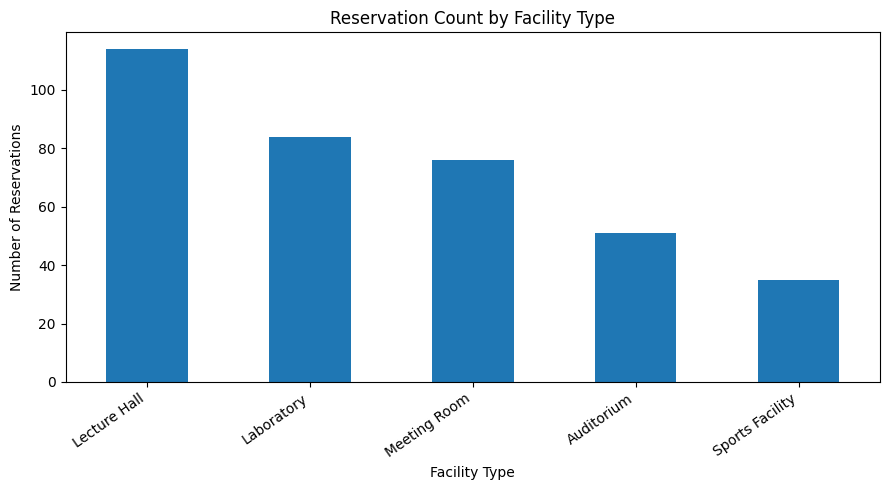


Cancellation/no-show by user category:
                      Total_Reservations  Cancellation_NoShow_Count  \
User_Category                                                         
Student Organization                  85                         39   
External User                         29                         13   
Administrative Staff                  56                         24   
Faculty                               79                         27   
Student                              103                         32   

                      Cancellation_NoShow_Percentage  
User_Category                                         
Student Organization                           45.88  
External User                                  44.83  
Administrative Staff                           42.86  
Faculty                                        34.18  
Student                                        31.07  

Finding 2: Student Organization has the highest observed cancellation/no-sho

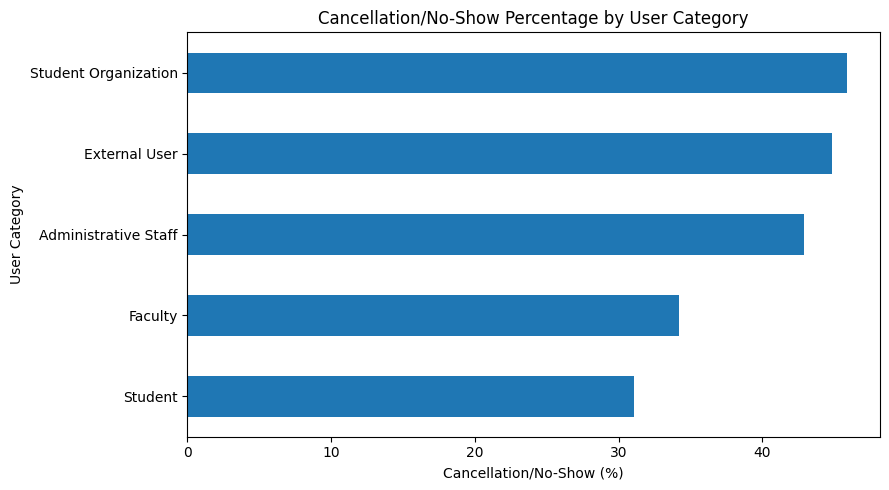


Lead-time category versus reservation outcome (counts):
Reservation_Outcome  Completed  Not Completed
Lead_Time_Category                           
Early Booking              132             47
Last Minute                 10             17
Medium Lead                 46             45
Short Lead                  34             26

Lead-time category versus outcome (row percentages):
Reservation_Outcome  Completed  Not Completed
Lead_Time_Category                           
Early Booking            73.74          26.26
Last Minute              37.04          62.96
Medium Lead              50.55          49.45
Short Lead               56.67          43.33


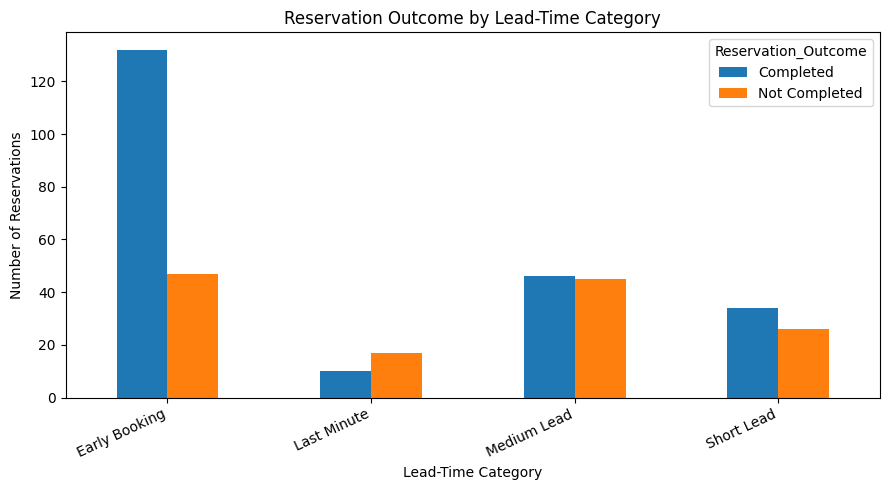


Finding 3: The lead-time category with the most records having a known outcome is Early Booking (179 records). Compare the row percentages above to assess how completion differs by lead time.

PART IV: DATA MINING AND PREDICTIVE MODELING

Predictors used: ['Facility_Type', 'User_Category', 'Reservation_Purpose', 'Lead_Time_Days', 'Participants', 'Facility_Capacity', 'Duration_Hours', 'Reservation_Weekday', 'Start_Hour']
Categorical predictors: ['Facility_Type', 'User_Category', 'Reservation_Purpose']
Numerical predictors: ['Lead_Time_Days', 'Participants', 'Facility_Capacity', 'Duration_Hours', 'Reservation_Weekday', 'Start_Hour']

Target distribution:
Reservation_Outcome
Completed        224
Not Completed    136
Name: count, dtype: int64

Leakage prevention: post-outcome fields and the original status used to derive the target are excluded from X. Imputation and encoding are fitted only on training data through the pipeline.

Training records: 288
Testing records: 72
Random state: 42

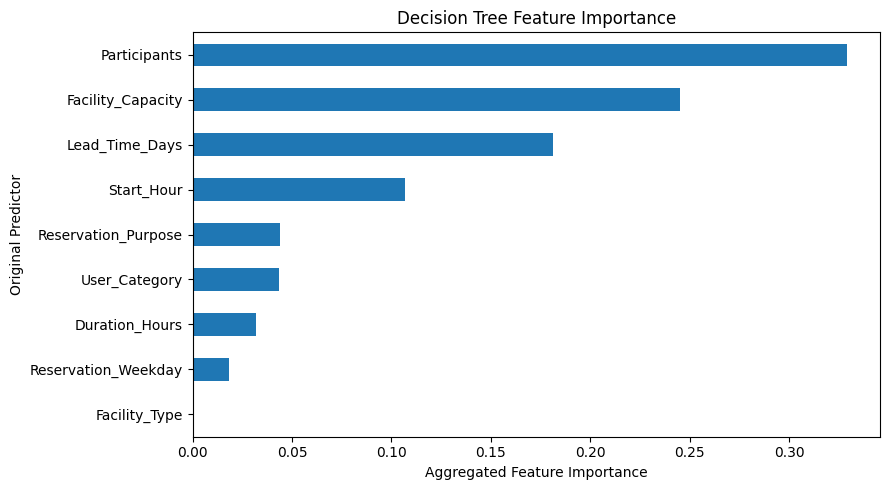


Model reliability assessment:
The model is an initial decision-support prototype, not proof of reliable real-world prediction. Assess class-specific recall, precision, F1, class balance, and performance on newer data before deployment.
Limitation: the dataset is synthetic and may not represent real university reservation behavior.
Improvement: evaluate on a larger, representative, temporally separate dataset and monitor performance over time.

PART V: REQUIREMENTS ANALYSIS

Use the actual findings printed in Part III and the metrics from Part IV to finalize the requirements. Do not claim an unobserved pattern.

Requirements table (complete the evidence column):
                                                               Finding / Evidence Requirement ID                                                                                                                                               Functional Requirement
            Insert the facility type and reservation count reported

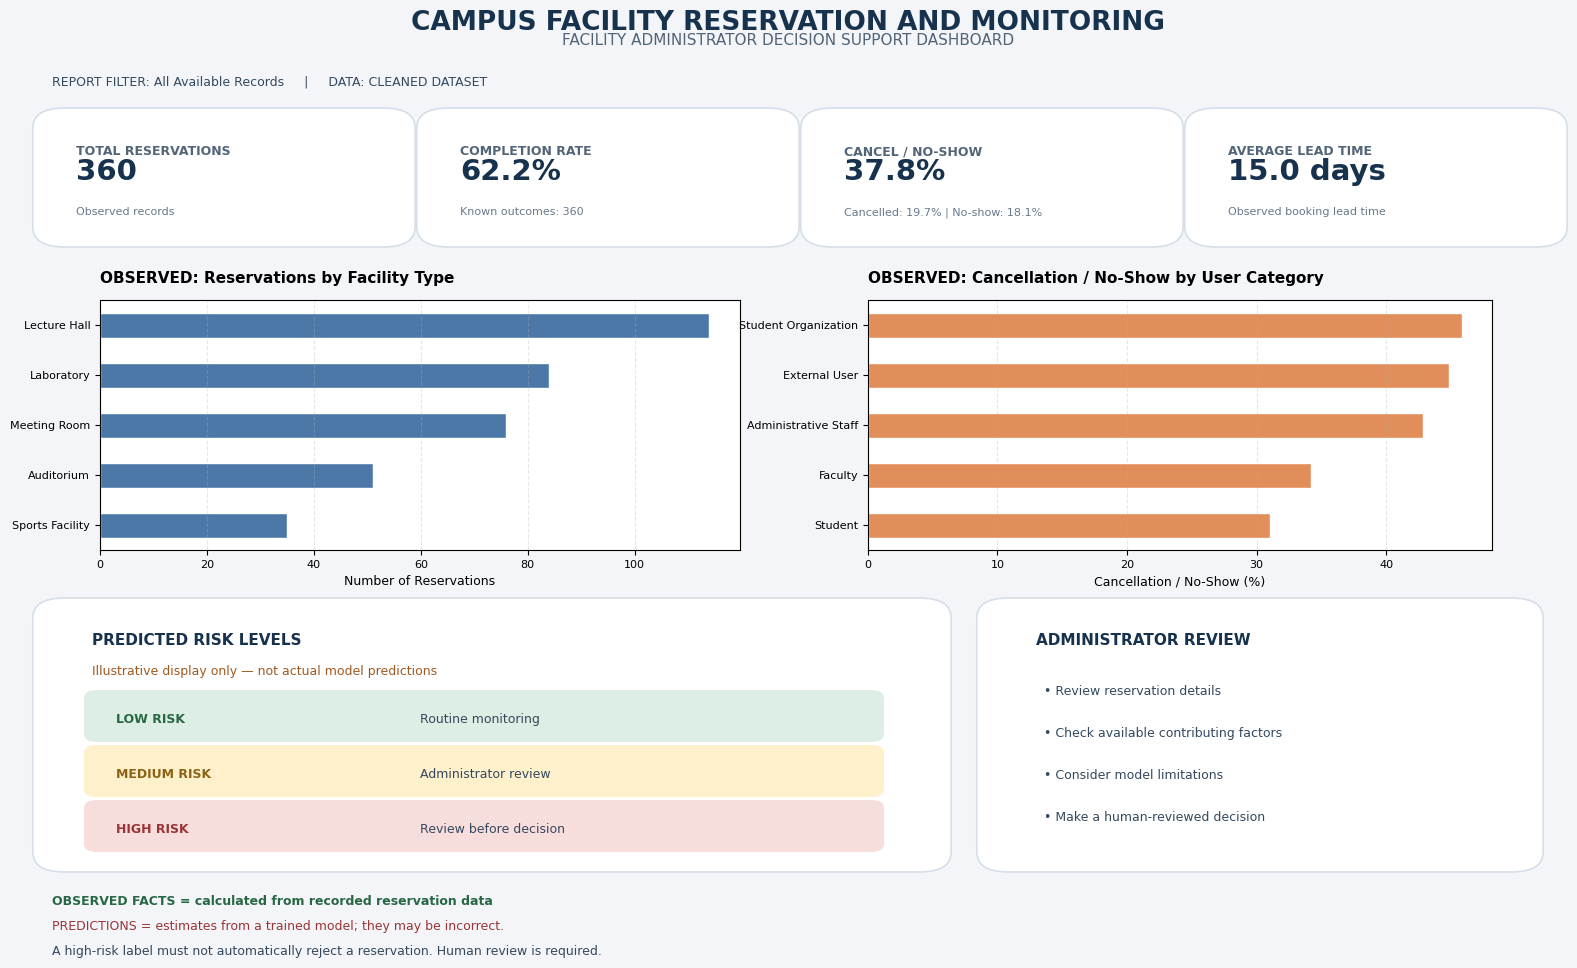


Dashboard image saved as: facility_reservation_dashboard.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


TASK 12: CRITICAL ANALYSIS

(a) A high-risk prediction should not automatically reject a reservation because a model can make errors and may reflect incomplete or biased historical data. An administrator should review the reservation before deciding.

(b) Poor data quality can distort statistics, introduce misleading patterns, and reduce model reliability. Missing, duplicated, or invalid records can lead to poor operational decisions.

(c) The dashboard should show the predicted risk level, available contributing factors, model limitations, and the distinction between predictions and observed facts. Feature importance does not prove causation.

FINAL OUTPUTS
1. Original dataset preserved in memory as original_df.
2. Cleaned dataset: facility_reservations_cleaned.csv
3. Requirements template: functional_requirements_template.csv

Final data-quality summary:
Original rows: 365
Cleaned rows: 360
Exact duplicate rows removed: 5
Missing cells in cleaned base dataset: 306
Engineered target 

In [ ]:
 ================================================================
# SAD LABORATORY EXAMINATION
# Data Mining and Systems Analysis Integration
# Campus Facility Reservation and Monitoring System
# ================================================================

# STEP 1: IMPORT LIBRARIES
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42



# ================================================================
# STEP 2: LOAD THE DATASET
# Campus Facility Reservation and Monitoring System
# ================================================================

# In Google Colab, upload your CSV when prompted.
possible_files = [
    "facility_reservations.csv",
    "facility_reservations - facility_reservations.csv"
]

FILE_PATH = next(
    (name for name in possible_files if os.path.exists(name)),
    None
)

try:
    from google.colab import files

    if FILE_PATH is None:
        print("Upload your facility reservations CSV file.")
        uploaded = files.upload()

        csv_files = [
            name for name in uploaded.keys()
            if name.lower().endswith(".csv")
        ]

        if not csv_files:
            raise FileNotFoundError(
                "No CSV file was uploaded. Please upload your dataset."
            )

        FILE_PATH = next(
            (
                name for name in csv_files
                if name == "facility_reservations - facility_reservations.csv"
            ),
            csv_files[0]
        )

except ImportError:
    pass

if FILE_PATH is None or not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        "Cannot find the dataset. Place your CSV file in the working directory."
    )

# Load the original dataset and preserve an untouched copy.
original_df = pd.read_csv(FILE_PATH)
df = original_df.copy(deep=True)

print("=" * 65)
print("PART I: DATASET ACQUISITION AND UNDERSTANDING")
print("=" * 65)

print("\nDataset file used:")
print(FILE_PATH)

# Task 1: Display the first 10 records.
print("\nFirst 10 records:")
print(original_df.head(10).to_string(index=False))

# Display the number of rows and columns.
print("\nDataset dimensions:")
print("Rows:", original_df.shape[0])
print("Columns:", original_df.shape[1])

# Display column names.
print("\nColumn names:")
print(original_df.columns.tolist())

# Display variable types.
print("\nData types:")
print(original_df.dtypes)

# Display summary statistics.
print("\nSummary statistics:")
print(original_df.describe(include="all").T)

# Check missing values.
print("\nMissing values before cleaning:")
print(original_df.isnull().sum())

# Check duplicate rows.
print(
    "\nDuplicate rows before cleaning:",
    original_df.duplicated().sum()
)

# Task 2: Identify variables and their roles.
data_dictionary = pd.DataFrame({
    "Variable": [
        "Reservation_ID",
        "Facility_Type",
        "User_Category",
        "Reservation_Purpose",
        "Lead_Time_Days",
        "Participants",
        "Facility_Capacity",
        "Duration_Hours",
        "Reservation_Weekday",
        "Start_Hour",
        "Usage_Status",
        "Actual_Attendance",
        "Cancellation_Days_Before"
    ],
    "Role": [
        "Transaction identifier",
        "Categorical predictor",
        "Categorical predictor",
        "Categorical predictor",
        "Numerical predictor",
        "Numerical predictor",
        "Numerical predictor",
        "Numerical predictor",
        "Numerical predictor",
        "Numerical predictor",
        "Outcome source",
        "Post-outcome information",
        "Post-outcome information"
    ]
})

print("\nData dictionary:")
print(data_dictionary.to_string(index=False))

print("\nFive or more predictor candidates available at submission:")
predictor_candidates = [
    "Facility_Type",
    "User_Category",
    "Reservation_Purpose",
    "Lead_Time_Days",
    "Participants",
    "Facility_Capacity",
    "Duration_Hours",
    "Reservation_Weekday",
    "Start_Hour"
]
print(predictor_candidates)

print("\nTarget variable:")
print("Reservation_Outcome (derived later from Usage_Status)")

print("\nCategorical variable examples:")
print(["Facility_Type", "User_Category"])

print("\nNumerical variable examples:")
print(["Lead_Time_Days", "Participants"])

# Task 3: Explain how data could be acquired.
print("\nData acquisition explanation:")
print(
    "The system could retrieve reservations using a database SELECT "
    "query or an authenticated API. A validation check should confirm "
    "that Reservation_ID is present and unique for each transaction."
)

# Validate that the dataset has the columns required by later steps.
required_columns = [
    "Reservation_ID",
    "Facility_Type",
    "User_Category",
    "Reservation_Purpose",
    "Lead_Time_Days",
    "Participants",
    "Facility_Capacity",
    "Duration_Hours",
    "Reservation_Weekday",
    "Start_Hour",
    "Usage_Status",
    "Actual_Attendance",
    "Cancellation_Days_Before"
]

missing_columns = [
    col for col in required_columns
    if col not in original_df.columns
]

if missing_columns:
    raise ValueError(
        "The uploaded CSV is missing required columns: "
        + ", ".join(missing_columns)
    )

print("\nColumn validation: PASSED")
print("STEP 2 completed successfully.")


# STEP 3: DATA CLEANING
print("\n" + "=" * 65)
print("PART II: DATA CLEANING AND FEATURE ENGINEERING")
print("=" * 65)

rows_before = len(df)
duplicates_before = int(df.duplicated().sum())
missing_before = int(df.isnull().sum().sum())

# Standardize text categories without altering missing values.
categorical_columns = [
    "Facility_Type", "User_Category", "Reservation_Purpose",
    "Usage_Status"
]

for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].apply(
            lambda x: x.strip().title()
            if isinstance(x, str) else x
        )

# Normalize known equivalent facility labels.
if "Facility_Type" in df.columns:
    df["Facility_Type"] = df["Facility_Type"].replace({
        "Lecturehall": "Lecture Hall",
        "Meetingroom": "Meeting Room",
        "Sportsfacility": "Sports Facility"
    })

# Convert numeric columns to numeric values.
numeric_columns = [
    "Lead_Time_Days", "Participants", "Facility_Capacity",
    "Duration_Hours", "Reservation_Weekday", "Start_Hour",
    "Actual_Attendance", "Cancellation_Days_Before"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Mark impossible values as missing instead of inventing replacements.
invalid_rules = {
    "Lead_Time_Days": lambda s: s < 0,
    "Participants": lambda s: s <= 0,
    "Facility_Capacity": lambda s: s <= 0,
    "Duration_Hours": lambda s: s <= 0,
    "Reservation_Weekday": lambda s: ~s.between(0, 6),
    "Start_Hour": lambda s: ~s.between(0, 23),
    "Actual_Attendance": lambda s: s < 0,
    "Cancellation_Days_Before": lambda s: s < 0
}

invalid_counts = {}
for col, rule in invalid_rules.items():
    if col in df.columns:
        invalid_mask = df[col].notna() & rule(df[col])
        invalid_counts[col] = int(invalid_mask.sum())
        df.loc[invalid_mask, col] = np.nan

# Attendance cannot exceed the number of participants.
if {"Actual_Attendance", "Participants"}.issubset(df.columns):
    excessive_attendance = (
        df["Actual_Attendance"].notna()
        & df["Participants"].notna()
        & (df["Actual_Attendance"] > df["Participants"])
    )
    invalid_counts["Attendance above participants"] = int(
        excessive_attendance.sum()
    )
    df.loc[excessive_attendance, "Actual_Attendance"] = np.nan

# Remove exact duplicate transactions, keeping the first occurrence.
df = df.drop_duplicates().copy()

# Missing categories remain missing in the cleaned dataset.
# For modeling, missing predictors will be imputed within the pipeline.
# Keep a clean-data copy before creating derived features.
cleaned_base = df.copy(deep=True)

print("\nCleaning decisions:")
print("- Preserved original_df as the untouched original dataset.")
print("- Standardized category capitalization and spacing.")
print("- Converted invalid numeric entries to missing values.")
print("- Removed exact duplicate rows, retaining the first occurrence.")
print("- Did not fabricate replacement values in the cleaned CSV.")
print("- Missing model predictors will be imputed using training data.")

print("\nInvalid values identified and marked missing:")
print(pd.Series(invalid_counts, name="Invalid_Count"))

print("\nMissing values after cleaning:")
print(cleaned_base.isnull().sum())

print("\nRows before cleaning:", rows_before)
print("Exact duplicates removed:", duplicates_before)
print("Rows after cleaning:", len(cleaned_base))
print("Total missing cells before cleaning:", missing_before)
print("Total missing cells after cleaning:",
      int(cleaned_base.isnull().sum().sum()))

# STEP 4: FEATURE ENGINEERING
df = cleaned_base.copy(deep=True)

# Lead-time categories use the exact examination thresholds.
def categorize_lead_time(value):
    if pd.isna(value):
        return np.nan
    if 0 <= value <= 2:
        return "Last Minute"
    elif 3 <= value <= 7:
        return "Short Lead"
    elif 8 <= value <= 14:
        return "Medium Lead"
    elif value > 14:
        return "Early Booking"
    return np.nan

df["Lead_Time_Category"] = df["Lead_Time_Days"].apply(
    categorize_lead_time
)

# Reservation outcome comes from Usage_Status.
# Unknown status values are not silently assigned a target.
def derive_outcome(status):
    if pd.isna(status):
        return np.nan
    status = str(status).strip().casefold()
    if status == "used":
        return "Completed"
    elif status in ("cancelled", "no-show"):
        return "Not Completed"
    return np.nan

df["Reservation_Outcome"] = df["Usage_Status"].apply(
    derive_outcome
)

# Attendance ratio is undefined when the denominator is zero/missing.
df["Attendance_Ratio"] = np.nan
valid_denominator = (
    df["Participants"].notna()
    & (df["Participants"] > 0)
    & df["Actual_Attendance"].notna()
)

df.loc[valid_denominator, "Attendance_Ratio"] = (
    df.loc[valid_denominator, "Actual_Attendance"]
    / df.loc[valid_denominator, "Participants"]
)
# Save cleaned data and engineered features.
df.to_csv("facility_reservations_cleaned.csv", index=False)

print("\nDerived variables preview:")
print(df[[
    "Lead_Time_Days", "Lead_Time_Category",
    "Usage_Status", "Reservation_Outcome",
    "Participants", "Actual_Attendance", "Attendance_Ratio"
]].head(10).to_string(index=False))

print("\nSaved: facility_reservations_cleaned.csv")

# STEP 5: EXPLORATORY DATA ANALYSIS
print("\n" + "=" * 65)
print("PART III: EXPLORATORY DATA ANALYSIS")
print("=" * 65)

# Question 1: Which facility type has the highest reservation count?
facility_counts = df["Facility_Type"].value_counts(dropna=True)

print("\nReservation count by facility type:")
print(facility_counts)

if not facility_counts.empty:
    top_facility = facility_counts.idxmax()
    print(
        f"\nFinding 1: {top_facility} has the highest observed "
        f"reservation count ({facility_counts.max()} out of "
        f"{facility_counts.sum()} records with a known facility type)."
    )

    plt.figure(figsize=(9, 5))
    facility_counts.plot(kind="bar")
    plt.title("Reservation Count by Facility Type")
    plt.xlabel("Facility Type")
    plt.ylabel("Number of Reservations")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

# Question 2: Cancellation/no-show percentage by user category.
valid_status = df["Usage_Status"].isin(["Used", "Cancelled", "No-Show"])
status_df = df.loc[
    valid_status & df["User_Category"].notna()
].copy()

status_df["Cancellation_NoShow"] = status_df[
    "Usage_Status"
].isin(["Cancelled", "No-Show"])

user_summary = status_df.groupby("User_Category").agg(
    Total_Reservations=("Cancellation_NoShow", "size"),
    Cancellation_NoShow_Count=("Cancellation_NoShow", "sum")
)

user_summary["Cancellation_NoShow_Percentage"] = (
    100 * user_summary["Cancellation_NoShow_Count"]
    / user_summary["Total_Reservations"]
)

print("\nCancellation/no-show by user category:")
print(user_summary.sort_values(
    "Cancellation_NoShow_Percentage", ascending=False
).round(2))

if not user_summary.empty:
    highest_user = user_summary[
        "Cancellation_NoShow_Percentage"
    ].idxmax()
    highest_rate = user_summary.loc[
        highest_user, "Cancellation_NoShow_Percentage"
    ]
    denominator = user_summary.loc[highest_user, "Total_Reservations"]

    print(
        f"\nFinding 2: {highest_user} has the highest observed "
        f"cancellation/no-show percentage ({highest_rate:.2f}%). "
        f"Denominator: {denominator} reservations in that category "
        "with a known user category and recognized status."
    )

    plt.figure(figsize=(9, 5))
    user_summary[
        "Cancellation_NoShow_Percentage"
    ].sort_values().plot(kind="barh")
    plt.title("Cancellation/No-Show Percentage by User Category")
    plt.xlabel("Cancellation/No-Show (%)")
    plt.ylabel("User Category")
    plt.tight_layout()
    plt.show()

# Question 3: Lead-time category and reservation outcome.
outcome_df = df.dropna(subset=[
    "Lead_Time_Category", "Reservation_Outcome"
])

outcome_counts = pd.crosstab(
    outcome_df["Lead_Time_Category"],
    outcome_df["Reservation_Outcome"]
)

print("\nLead-time category versus reservation outcome (counts):")
print(outcome_counts)

if not outcome_counts.empty:
    outcome_percentages = pd.crosstab(
        outcome_df["Lead_Time_Category"],
        outcome_df["Reservation_Outcome"],
        normalize="index"
    ) * 100

    print("\nLead-time category versus outcome (row percentages):")
    print(outcome_percentages.round(2))

    outcome_counts.plot(kind="bar", figsize=(9, 5))
    plt.title("Reservation Outcome by Lead-Time Category")
    plt.xlabel("Lead-Time Category")
    plt.ylabel("Number of Reservations")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

    # Evidence-based description of the largest observed group.
    group_totals = outcome_counts.sum(axis=1)
    print(
        "\nFinding 3: The lead-time category with the most "
        f"records having a known outcome is {group_totals.idxmax()} "
        f"({group_totals.max()} records). Compare the row percentages "
        "above to assess how completion differs by lead time."
    )

# STEP 6: DECISION TREE CLASSIFICATION
print("\n" + "=" * 65)
print("PART IV: DATA MINING AND PREDICTIVE MODELING")
print("=" * 65)

# Only information available at submission time is used.
# Explicitly excluded:
# Usage_Status, Actual_Attendance, Cancellation_Days_Before,
# Reservation_Outcome, Attendance_Ratio, and Reservation_ID.
predictors = [
    "Facility_Type",
    "User_Category",
    "Reservation_Purpose",
    "Lead_Time_Days",
    "Participants",
    "Facility_Capacity",
    "Duration_Hours",
    "Reservation_Weekday",
    "Start_Hour"
]

target = "Reservation_Outcome"

model_data = df.dropna(subset=[target]).copy()
X = model_data[predictors].copy()
y = model_data[target].copy()

# Separate categorical and numerical predictors.
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("\nPredictors used:", predictors)
print("Categorical predictors:", categorical_features)
print("Numerical predictors:", numerical_features)
print("\nTarget distribution:")
print(y.value_counts())

print(
    "\nLeakage prevention: post-outcome fields and the original status "
    "used to derive the target are excluded from X. Imputation and "
    "encoding are fitted only on training data through the pipeline."
)

if y.nunique() < 2:
    print(
        "\nModel not trained: the available target contains fewer "
        "than two classes. A binary classifier cannot be evaluated "
        "meaningfully with this data."
    )
elif y.value_counts().min() < 2:
    print(
        "\nModel not trained: at least one class has fewer than two "
        "records, so a stratified train/test split is not supported."
    )
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y
    )

    # Impute numerical missing values using training-set medians.
    # Impute categorical missing values using the most frequent value.
    from sklearn.impute import SimpleImputer

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(transformers=[
        ("numeric", numeric_pipeline, numerical_featur

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=RANDOM_STATE,
            max_depth=5,
            min_samples_leaf=5,
            class_weight="balanced"
        ))
    ])

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("\nTraining records:", len(X_train))
    print("Testing records:", len(X_test))
    print("Random state:", RANDOM_STATE)

    print("\nConfusion matrix:")
    labels = model.named_steps["classifier"].classes_
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    print(pd.DataFrame(
        cm,
        index=[f"Actual {label}" for label in labels],
        columns=[f"Predicted {label}" for label in labels]
    ))

    print("\nEvaluation metrics:")
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision (weighted): {precision:.4f}")
    print(f"Recall (weighted):    {recall:.4f}")
    print(f"F1-score (weighted):  {f1:.4f}")

    print("\nClassification report:")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

    # Extract feature importance after one-hot encoding.
    fitted_preprocessor = model.named_steps["preprocessor"]
    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = model.named_steps[
        "classifier"
    ].feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False)

    # Aggregate one-hot encoded columns back to their original feature.
    def original_feature_name(encoded_name):
        name = encoded_name.split("__", 1)[-1]
        for col in predictors:
            if name == col or name.startswith(col + "_"):
                return col
        return name

    importance_df["Original_Predictor"] = (
        importance_df["Feature"].apply(original_feature_name)
    )

    grouped_importance = importance_df.groupby(
        "Original_Predictor"
    )["Importance"].sum().sort_values(ascending=False)

    print("\nTop three influential original predictors:")
    print(grouped_importance.head(3))

    if not grouped_importance.empty:
        plt.figure(figsize=(9, 5))
        grouped_importance.head(10).sort_values().plot(kind="barh")
        plt.title("Decision Tree Feature Importance")
        plt.xlabel("Aggregated Feature Importance")
        plt.ylabel("Original Predictor")
        plt.tight_layout()
        plt.show()

    print("\nModel reliability assessment:")
    print(
        "The model is an initial decision-support prototype, not proof "
        "of reliable real-world prediction. Assess class-specific "
        "recall, precision, F1, class balance, and performance on newer "
        "data before deployment."
    )
    print(
        "Limitation: the dataset is synthetic and may not represent "
        "real university reservation behavior."
    )
    print(
        "Improvement: evaluate on a larger, representative, temporally "
        "separate dataset and monitor performance over time."
    )

# STEP 7: EVIDENCE-BASED REQUIREMENTS
print("\n" + "=" * 65)
print("PART V: REQUIREMENTS ANALYSIS")
print("=" * 65)

print(
    "\nUse the actual findings printed in Part III and the metrics "
    "from Part IV to finalize the requirements. Do not claim an "
    "unobserved pattern."
)

requirements = pd.DataFrame([
    {
        "Finding / Evidence": (
            "Insert the facility type and reservation count reported "
            "in Finding 1."
        ),
        "Requirement ID": "FR-DM-01",
        "Functional Requirement": (
            "The system shall display reservation counts by facility "
            "type for the selected reporting period."
        )
    },
    {
        "Finding / Evidence": (
            "Insert the user category and percentage reported "
            "in Finding 2."
        ),
        "Requirement ID": "FR-DM-02",
        "Functional Requirement": (
            "The system shall calculate and display cancellation/no-show "
            "percentages by user category, including the denominator."
        )
    },
    {
        "Finding / Evidence": (
            "Use the measured model performance and the observed "
            "lead-time/outcome comparison."
        ),
        "Requirement ID": "FR-DM-03",
        "Functional Requirement": (
            "The system shall display predicted reservation outcome "
            "risk separately from observed reservation statistics and "
            "show model evaluation information to administrators."
        )
    }
])

print("\nRequirements table (complete the evidence column):")
print(requirements.to_string(index=False))
requirements.to_csv("functional_requirements_template.csv", index=False)
print("\nSaved: functional_requirements_template.csv")

print("\nUse case diagram guidance:")
print("""
System boundary: Campus Facility Reservation and Monitoring System

Actors:
- Facility Administrator
- Reservation User

Use cases:
- View Reservation Statistics
- Analyze Cancellation and No-Show Patterns
- View Reservation Outcome Risk Predictions
- Review Model Performance
- Manage Facility Reservations

Associate Facility Administrator with the four analytical use cases.
Associate Reservation User with Manage Facility Reservations.
Only add <<include>> or <<extend>> when the actual use-case
relationship justifies it.
""")


# STEP 8: DECISION SUPPORT AND CRITICAL ANALYSIS
print("\n" + "=" * 65)
print("PART VI: DECISION SUPPORT AND CRITICAL ANALYSIS")
print("=" * 65)

from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import PercentFormatter

# ------------------------------------------------
# 1. PREPARE OBSERVED DATA FROM THE CLEANED DATASET
# ------------------------------------------------
dashboard_df = df.copy()

total_reservations = len(dashboard_df)

known_outcomes = dashboard_df["Reservation_Outcome"].dropna()
completion_rate = (
    (known_outcomes == "Completed").mean() * 100
    if len(known_outcomes) > 0 else 0
)

valid_statuses = dashboard_df[
    dashboard_df["Usage_Status"].isin(["Used", "Cancelled", "No-Show"])
].copy()

cancel_count = (valid_statuses["Usage_Status"] == "Cancelled").sum()
noshow_count = (valid_statuses["Usage_Status"] == "No-Show").sum()
valid_count = len(valid_statuses)

cancel_rate = cancel_count / valid_count * 100 if valid_count else 0
noshow_rate = noshow_count / valid_count * 100 if valid_count else 0

avg_lead = dashboard_df["Lead_Time_Days"].mean()

facility_counts = dashboard_df["Facility_Type"].value_counts().head(8)

user_data = valid_statuses.dropna(subset=["User_Category"]).copy()
user_data["Cancel_NoShow"] = user_data["Usage_Status"].isin(
    ["Cancelled", "No-Show"]
)

if not user_data.empty:
    user_summary = user_data.groupby("User_Category").agg(
        Total=("Cancel_NoShow", "size"),
        Cancel_NoShow=("Cancel_NoShow", "sum")
    )
    user_summary["Rate"] = (
        user_summary["Cancel_NoShow"] / user_summary["Total"] * 100
    )
    user_summary = user_summary.sort_values("Rate", ascending=True)
else:
    user_summary = pd.DataFrame(columns=["Total", "Cancel_NoShow", "Rate"])

# ------------------------------------------------
# 2. CREATE THE DASHBOARD IMAGE
# ------------------------------------------------
fig = plt.figure(figsize=(16, 10), facecolor="#F3F5F9")

fig.suptitle(
    "CAMPUS FACILITY RESERVATION AND MONITORING",
    fontsize=19, fontweight="bold", color="#17324D", y=0.97
)

fig.text(
    0.5, 0.935,
    "FACILITY ADMINISTRATOR DECISION SUPPORT DASHBOARD",
    ha="center", fontsize=11, color="#526477"
)

# Header and filter bar
fig.text(
    0.04, 0.895,
    "REPORT FILTER: All Available Records     |     DATA: CLEANED DATASET",
    fontsize=9, color="#34495E"
)

# KPI card helper
def add_kpi(x, y, width, height, title, value, subtitle):
    card = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.012,rounding_size=0.02",
        transform=fig.transFigure,
        facecolor="white", edgecolor="#D6DEE8", linewidth=1.2
    )
    fig.patches.append(card)

    fig.text(
        x + 0.015, y + height - 0.035,
        title, fontsize=9, color="#526477", fontweight="bold"
    )
    fig.text(
        x + 0.015, y + 0.055,
        value, fontsize=21, color="#17324D", fontweight="bold"
    )
    fig.text(
        x + 0.015, y + 0.020,
        subtitle, fontsize=8, color="#68798B"
    )

kpi_y = 0.745
kpi_w = 0.215
kpi_h = 0.115
kpi_gap = 0.025

add_kpi(
    0.04, kpi_y, kpi_w, kpi_h,
    "TOTAL RESERVATIONS",
    f"{total_reservations:,}",
    "Observed records"
)

add_kpi(
    0.04 + (kpi_w + kpi_gap), kpi_y, kpi_w, kpi_h,
    "COMPLETION RATE",
    f"{completion_rate:.1f}%",
    f"Known outcomes: {len(known_outcomes):,}"
)

add_kpi(
    0.04 + 2 * (kpi_w + kpi_gap), kpi_y, kpi_w, kpi_h,
    "CANCEL / NO-SHOW",
    f"{cancel_rate + noshow_rate:.1f}%",
    f"Cancelled: {cancel_rate:.1f}% | No-show: {noshow_rate:.1f}%"
)

avg_lead_text = f"{avg_lead:.1f} days" if pd.notna(avg_lead) else "N/A"
add_kpi(
    0.04 + 3 * (kpi_w + kpi_gap), kpi_y, kpi_w, kpi_h,
    "AVERAGE LEAD TIME",
    avg_lead_text,
    "Observed booking lead time"
)

# ------------------------------------------------
# 3. CHART: RESERVATIONS BY FACILITY
# ------------------------------------------------
ax1 = fig.add_axes([0.07, 0.43, 0.40, 0.25])
ax1.set_facecolor("white")

if not facility_counts.empty:
    facility_counts.sort_values().plot(
        kind="barh", ax=ax1, color="#4C78A8", edgecolor="white"
    )
    ax1.set_xlabel("Number of Reservations", fontsize=9)
    ax1.set_ylabel("")
    ax1.tick_params(axis="y", labelsize=8)
    ax1.tick_params(axis="x", labelsize=8)
    ax1.grid(axis="x", linestyle="--", alpha=0.3)
else:
    ax1.text(0.5, 0.5, "No facility data available",
             ha="center", va="center", transform=ax1.transAxes)

ax1.set_title(
    "OBSERVED: Reservations by Facility Type",
    loc="left", fontsize=11, fontweight="bold", pad=12
)

# ------------------------------------------------
# 4. CHART: CANCELLATION / NO-SHOW BY USER CATEGORY
# ------------------------------------------------
ax2 = fig.add_axes([0.55, 0.43, 0.39, 0.25])
ax2.set_facecolor("white")

if not user_summary.empty:
    user_summary["Rate"].plot(
        kind="barh", ax=ax2, color="#E28E5B", edgecolor="white"
    )
    ax2.set_xlabel("Cancellation / No-Show (%)", fontsize=9)
    ax2.set_ylabel("")
    ax2.tick_params(axis="y", labelsize=8)
    ax2.tick_params(axis="x", labelsize=8)
    ax2.grid(axis="x", linestyle="--", alpha=0.3)
else:
    ax2.text(0.5, 0.5, "No recognized status data available",
             ha="center", va="center", transform=ax2.transAxes)

ax2.set_title(
    "OBSERVED: Cancellation / No-Show by User Category",
    loc="left", fontsize=11, fontweight="bold", pad=12
)

# ------------------------------------------------
# 5. RISK PANEL: CLEARLY LABELLED AS ILLUSTRATIVE
# ------------------------------------------------
risk_box = FancyBboxPatch(
    (0.04, 0.12), 0.55, 0.25,
    boxstyle="round,pad=0.012,rounding_size=0.02",
    transform=fig.transFigure,
    facecolor="white", edgecolor="#D6DEE8", linewidth=1.2
)
fig.patches.append(risk_box)

fig.text(
    0.065, 0.335,
    "PREDICTED RISK LEVELS",
    fontsize=11, fontweight="bold", color="#17324D"
)
fig.text(
    0.065, 0.305,
    "Illustrative display only — not actual model predictions",
    fontsize=9, color="#A05A20"
)

risk_items = [
    ("LOW RISK", "Routine monitoring", "#DDEFE4", "#286744"),
    ("MEDIUM RISK", "Administrator review", "#FFF0CC", "#8A6415"),
    ("HIGH RISK", "Review before decision", "#F8DDDD", "#9A3535")
]

for i, (label, description, bg, fg) in enumerate(risk_items):
    y = 0.255 - i * 0.055

    risk_card = FancyBboxPatch(
        (0.065, y - 0.012), 0.49, 0.042,
        boxstyle="round,pad=0.005,rounding_size=0.008",
        transform=fig.transFigure,
        facecolor=bg, edgecolor="none"
    )
    fig.patches.append(risk_card)

    fig.text(
        0.08, y + 0.002, label,
        fontsize=9, fontweight="bold", color=fg
    )
    fig.text(
        0.27, y + 0.002, description,
        fontsize=9, color="#34495E"
    )

# ------------------------------------------------
# 6. ADMINISTRATOR REVIEW PANEL
# ------------------------------------------------
admin_box = FancyBboxPatch(
    (0.63, 0.12), 0.33, 0.25,
    boxstyle="round,pad=0.012,rounding_size=0.02",
    transform=fig.transFigure,
    facecolor="white", edgecolor="#D6DEE8", linewidth=1.2
)
fig.patches.append(admin_box)

fig.text(
    0.655, 0.335,
    "ADMINISTRATOR REVIEW",
    fontsize=11, fontweight="bold", color="#17324D"
)

admin_lines = [
    "Review reservation details",
    "Check available contributing factors",
    "Consider model limitations",
    "Make a human-reviewed decision"
]

for i, line in enumerate(admin_lines):
    fig.text(
        0.66, 0.285 - i * 0.042,
        f"• {line}", fontsize=9, color="#34495E"
    )

# ------------------------------------------------
# 7. FOOTER: FACTS VS PREDICTIONS
# ------------------------------------------------
fig.text(
    0.04, 0.075,
    "OBSERVED FACTS = calculated from recorded reservation data",
    fontsize=9, fontweight="bold", color="#286744"
)
fig.text(
    0.04, 0.050,
    "PREDICTIONS = estimates from a trained model; they may be incorrect.",
    fontsize=9, color="#9A3535"
)
fig.text(
    0.04, 0.025,
    "A high-risk label must not automatically reject a reservation. "
    "Human review is required.",
    fontsize=9, color="#34495E"
)

plt.savefig(
    "facility_reservation_dashboard.png",
    dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor()
)
plt.show()

print("\nDashboard image saved as: facility_reservation_dashboard.png")

# Automatically download the image in Google Colab
try:
    from google.colab import files
    files.download("facility_reservation_dashboard.png")
except ImportError:
    print("Outside Google Colab: find the PNG in the current working folder.")

# ------------------------------------------------
# 8. TASK 12: CRITICAL ANALYSIS
# ------------------------------------------------
print("\nTASK 12: CRITICAL ANALYSIS")

print(
    "\n(a) A high-risk prediction should not automatically reject a "
    "reservation because a model can make errors and may reflect "
    "incomplete or biased historical data. An administrator should "
    "review the reservation before deciding."
)

print(
    "\n(b) Poor data quality can distort statistics, introduce misleading "
    "patterns, and reduce model reliability. Missing, duplicated, or "
    "invalid records can lead to poor operational decisions."
)

print(
    "\n(c) The dashboard should show the predicted risk level, available "
    "contributing factors, model limitations, and the distinction "
    "between predictions and observed facts. Feature importance "
    "does not prove causation."
)


# STEP 9: SAVE FINAL DATA AND SUMMARY
print("\n" + "=" * 65)
print("FINAL OUTPUTS")
print("=" * 65)

print("1. Original dataset preserved in memory as original_df.")
print("2. Cleaned dataset: facility_reservations_cleaned.csv")
print("3. Requirements template: functional_requirements_template.csv")

print("\nFinal data-quality summary:")
print("Original rows:", len(original_df))
print("Cleaned rows:", len(cleaned_base))
print("Exact duplicate rows removed:", duplicates_before)
print(
    "Missing cells in cleaned base dataset:",
    int(cleaned_base.isnull().sum().sum())
)
print("Engineered target counts:")
print(df["Reservation_Outcome"].value_counts(dropna=False))

print("\nExecution complete.")